# 03 · Fairness check (on IBM LinuxONE)
The AML data has no demographics, so we audit proxies a bank could be unfair along: **payment currency** (migrant communities often send in Rupee, Yuan, Shekel...), **payment format**, and **the sender's bank size**. Measure: the false-alarm rate, honest payments that were still warned or held.

In [1]:
import sys, os, platform, subprocess
sys.path.insert(0, os.path.expanduser("~/scamshield/src"))
import xgboost  # before torch (see training.py)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
SHARED = os.path.expanduser("~/shared")
RAW = f"{SHARED}/aml"
print(platform.machine(), platform.platform())
print(subprocess.run("grep -E '^Type:' /proc/sysinfo; lscpu | grep -io nnpa | head -1", shell=True,
                     capture_output=True, text=True).stdout)

s390x Linux-6.8.0-147-generic-s390x-with-glibc2.39
Type:                 9175
nnpa



In [2]:
from scamshield import fairness as F
dec = pd.read_csv(f"{SHARED}/data/test_decisions.csv")
g = F.attach_groups(dec)
F.disparity_summary(g).round(4)

,attribute,groups,min_false_alarm,max_false_alarm,max_over_min,worst_group,best_group
0,currency_paid,15,0.0032,0.0229,7.1307,Brazil Real,Bitcoin
1,payment_format,6,0.0009,0.1041,112.8630,ACH,Cheque
2,bank_size,4,0.0074,0.0255,3.4444,<100,10k+


In [3]:
for a in ["currency_paid", "payment_format", "bank_size"]:
    display(F.group_rates(g, a).round(4))

,payments,false_alarm_rate,false_hold_rate,laundering_caught,vs_overall
currency_paid,,,,,
US Dollar,322621,0.0165,0.0006,0.8261,1.0039
Euro,198231,0.0156,0.0005,0.8118,0.9493
Swiss Franc,39678,0.0165,0.0005,0.7407,0.9994
Yuan,36201,0.0175,0.0007,0.9355,1.0637
Shekel,32752,0.0178,0.0005,0.8235,1.0826
Rupee,32200,0.0179,0.0005,0.8500,1.0862
UK Pound,30922,0.0177,0.0004,0.5652,1.0723
Ruble,26513,0.0163,0.0003,0.8182,0.9919
Yen,26289,0.0188,0.0006,0.8750,1.1394


,payments,false_alarm_rate,false_hold_rate,laundering_caught,vs_overall
payment_format,,,,,
Cheque,347008,0.0009,0.0000,0.0167,0.0560
Credit Card,250247,0.0038,0.0000,0.0000,0.2306
ACH,119195,0.1041,0.0037,0.9376,6.3170
Cash,91737,0.0032,0.0000,0.0000,0.1972
Wire,30276,0.0081,0.0000,NaN,0.4891
Bitcoin,24329,0.0028,0.0000,0.1000,0.1697


,payments,false_alarm_rate,false_hold_rate,laundering_caught,vs_overall
bank_size,,,,,
1k-10k,392221,0.0130,0.0004,0.9178,0.7876
100-1k,257123,0.0223,0.0008,0.9317,1.3543
10k+,113823,0.0074,0.0002,0.2566,0.4500
<100,99625,0.0255,0.0006,0.9452,1.5501


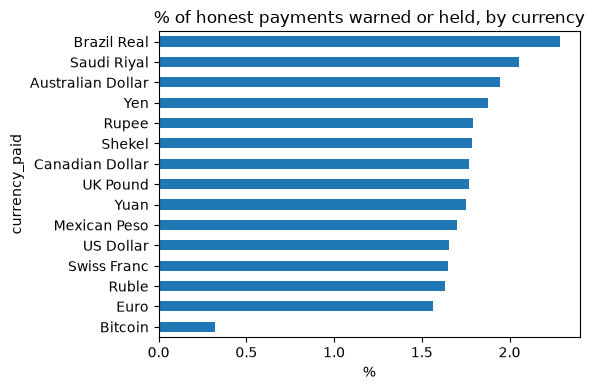

In [4]:
r = F.group_rates(g, "currency_paid")
(r.false_alarm_rate * 100).sort_values().plot.barh(figsize=(6, 4), title="% of honest payments warned or held, by currency")
plt.xlabel("%"); plt.tight_layout()

**Findings.** Across fiat currencies false-alarm rates are similar (about 1.6-2.3%), so no migrant-community currency is singled out. Honest **ACH** payments carry most of the friction (about 11% warned) because most laundering moves by ACH; laundering by cash, cheque or card is mostly missed. Customers of the **smallest banks** see about 5x the false alarms of the biggest banks. **Mitigations:** warnings never block (the customer decides), holds always go to a human, and per-segment warning budgets are the next step, re-measured with this notebook.